In [1]:
# 三大件
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tushare as ts
%matplotlib inline

In [2]:
import sys
import os
sys.path.append("../../FinanceDataSource")
from FinanceDataSource import get_cn_stocks
from FinanceDataSource import get_cn_bars_all

# 简单实现

In [3]:
## 取得所有的股票
_all_cn_stock = get_cn_stocks()
# 我要对这个列表进行遍历。
_all_cn_stock

['000001.XSHE',
 '000002.XSHE',
 '000004.XSHE',
 '000005.XSHE',
 '000006.XSHE',
 '000007.XSHE',
 '000008.XSHE',
 '000009.XSHE',
 '000010.XSHE',
 '000011.XSHE',
 '000012.XSHE',
 '000014.XSHE',
 '000016.XSHE',
 '000017.XSHE',
 '000018.XSHE',
 '000019.XSHE',
 '000020.XSHE',
 '000021.XSHE',
 '000022.XSHE',
 '000023.XSHE',
 '000025.XSHE',
 '000026.XSHE',
 '000027.XSHE',
 '000028.XSHE',
 '000029.XSHE',
 '000030.XSHE',
 '000031.XSHE',
 '000032.XSHE',
 '000034.XSHE',
 '000035.XSHE',
 '000036.XSHE',
 '000037.XSHE',
 '000038.XSHE',
 '000039.XSHE',
 '000040.XSHE',
 '000042.XSHE',
 '000043.XSHE',
 '000045.XSHE',
 '000046.XSHE',
 '000048.XSHE',
 '000049.XSHE',
 '000050.XSHE',
 '000055.XSHE',
 '000056.XSHE',
 '000058.XSHE',
 '000059.XSHE',
 '000060.XSHE',
 '000061.XSHE',
 '000062.XSHE',
 '000063.XSHE',
 '000065.XSHE',
 '000066.XSHE',
 '000068.XSHE',
 '000069.XSHE',
 '000070.XSHE',
 '000078.XSHE',
 '000088.XSHE',
 '000089.XSHE',
 '000090.XSHE',
 '000096.XSHE',
 '000099.XSHE',
 '000100.XSHE',
 '000150

In [4]:
print(get_cn_bars_all("000591.XSHE",fields=['close','datetime'],convert_to_dataframe=True))

               close
                    
2005-01-04  0.758336
2005-01-05  0.780357
2005-01-06  0.773475
2005-01-07  0.774851
2005-01-10  0.796872
2005-01-11  0.792743
2005-01-12  0.783109
2005-01-13  0.791367
2005-01-14  0.781733
2005-01-17  0.755583
2005-01-18  0.770723
2005-01-19  0.765217
2005-01-20  0.761088
2005-01-21  0.766594
2005-01-24  0.785862
2005-01-25  0.778980
2005-01-26  0.777604
2005-01-27  0.772099
2005-01-28  0.767970
2005-01-31  0.736315
2005-02-01  0.697779
2005-02-02  0.732186
2005-02-03  0.710166
2005-02-04  0.714295
2005-02-16  0.714295
2005-02-17  0.715671
2005-02-18  0.707413
2005-02-21  0.718423
2005-02-22  0.751454
2005-02-23  0.756960
...              ...
2018-02-26  5.020000
2018-02-27  4.970000
2018-02-28  4.960000
2018-03-01  5.070000
2018-03-02  5.050000
2018-03-05  5.070000
2018-03-06  5.060000
2018-03-07  5.060000
2018-03-08  5.100000
2018-03-09  5.120000
2018-03-12  5.180000
2018-03-13  5.160000
2018-03-14  5.080000
2018-03-15  5.070000
2018-03-16  5

In [5]:
df_list=[]
# 我的做法是先遍历所有的股票。
for _stock in get_cn_stocks():
    # 然后取得每个股票的信息。
    _df=get_cn_bars_all(_stock,fields=['close','datetime'],convert_to_dataframe=True)
    # 这个_df有2项目，一个是日期，一个是收盘价。
    # 因为这个是用diff做的，
    _df_2=_df.shift(0-250)
    _df['close_diff_250']=(_df['close']-_df_2['close'])/_df_2['close']*100
    _df['code']=_stock # 股票代码
    _df['date']=_df.index # 日期
    _df=_df.reset_index(level=None,drop=True) #删除index
    #删除无效的数据。
    _df=_df.dropna(axis=0)
    df_list.append(_df)

df_all=pd.concat(df_list)


In [6]:
#看看总共多少数据
len(df_all)

5562658

In [7]:
df_all_2=df_all.sort_values(by='close_diff_250',ascending=False)

In [8]:
df_all_2

,close,close_diff_250,code,date
2381,39.801967,1151.634190,600654.XSHG,2015-06-17
647,87.374670,1123.734879,000878.XSHE,2007-10-17
644,88.756869,1122.546398,000878.XSHE,2007-10-12
2382,38.855961,1110.466075,600654.XSHG,2015-06-18
642,90.445125,1109.159423,000878.XSHE,2007-10-10
646,87.897931,1102.434078,000878.XSHE,2007-10-16
2395,37.979661,1086.864391,600654.XSHG,2015-11-16
643,91.027623,1082.176918,000878.XSHE,2007-10-11
609,18.234015,1081.408996,000758.XSHE,2007-10-12
2379,41.484863,1075.208570,600654.XSHG,2015-06-15


In [9]:
# 经过如上的排序，我发现最高的那部分都是2007年10月11月的。，不由得是我想要看看这个日期是否跟大盘相关。
# 我想要做一个统计。以日期为分组，将涨幅部分求和。比如2007-11-02日，的所有股票的涨幅求平均值，平均值才有意义吧。
grouped=df_all_2.groupby(by='date')
#我只想对涨幅部分求和
df_groupby_date_close_diff_250=grouped['close_diff_250'].agg([np.mean,np.std])
df_groupby_date_close_diff_250

,mean,std
date,,
2005-01-04,13.220043,35.814971
2005-01-05,14.524971,36.570916
2005-01-06,13.508242,36.641671
2005-01-07,14.152155,37.315110
2005-01-10,15.397351,38.301489
2005-01-11,15.763223,38.519380
2005-01-12,15.151831,38.474162
2005-01-13,14.684839,37.873199
2005-01-14,12.855418,36.902685


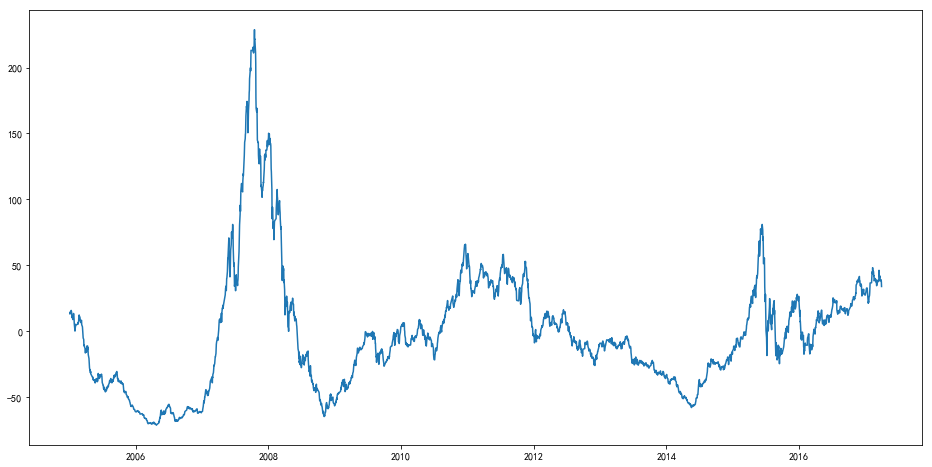

In [10]:
plt. figure(figsize=(16, 8)) 
plt.plot(df_groupby_date_close_diff_250.index,df_groupby_date_close_diff_250['mean'])

# 函数形式

In [11]:
# 将如上的做成函数形式，简单点，就是输入是股票列表，输出是涨幅
# 这个函数最大的问题是，如果设置为1年，那么就是取得持有一年的股票的增幅情况，但问题是。这个是未来函数啊。
# 最根本的原因是时间以当前时间为准，在通过shift来减去多少天前的股价，来判断增幅的。
# 那问题就来了
# 比如我根据2010年数据显示到达我需要的增幅，然后我买股票了，但是，从2009年到2010年是涨的，而从2010年到2011年是跌的。
# 而如果我根据多少天前的时间为准，也同样有这个问题。

def get_stock_gains(lst_stock,shift_num=250):
    """取得股票的增幅情况，请注意这个是持有一年的股票的增幅情况"""
    df_list=[]
    # 我的做法是先遍历所有的股票。
    for _stock in lst_stock:
        # 然后取得每个股票的信息。
        _df=get_cn_bars_all(_stock,fields=['close','datetime'],convert_to_dataframe=True)
        # 这个_df有2项目，一个是日期，一个是收盘价。
        # 因为这个是用diff做的，
        _df_2=_df.shift(shift_num)
        _df['close_diff']=(_df['close']-_df_2['close'])/_df_2['close']*100
        _df['code']=_stock # 股票代码
        _df['date']=_df.index # 日期
        _df=_df.reset_index(level=None,drop=True) #删除index
        #删除无效的数据。
        _df=_df.dropna(axis=0)
        df_list.append(_df)
    df_all=pd.concat(df_list)
    return df_all    

In [12]:
def get_gains_mean(df):
    grouped=df.groupby(by='date')
    #我只想对涨幅部分求和
    return grouped['close_diff'].agg([np.mean,np.std])

Wall time: 34 s


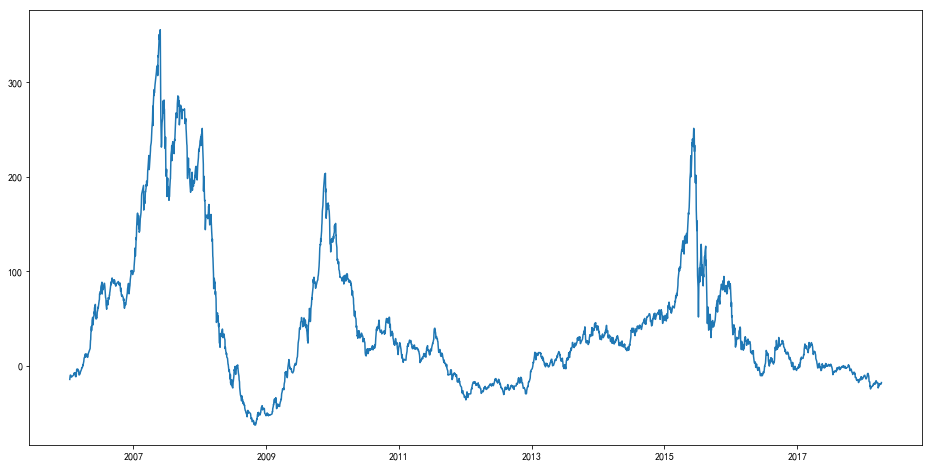

In [13]:
%time df_2_1=get_gains_mean(get_stock_gains(get_cn_stocks()))
plt. figure(figsize=(16, 8)) 
plt.plot(df_2_1.index,df_2_1['mean'])

In [14]:
# 设计一个总的函数吧。
def get_stock_gains_2(lst_stock,shift_num=250):
    df_2_1=get_gains_mean(get_stock_gains(lst_stock,shift_num))
    plt. figure(figsize=(16, 8))
    plt.plot(df_2_1.index,df_2_1['mean'])

# 查看根据不同时间间隔的涨幅情况

## 根据一个季度

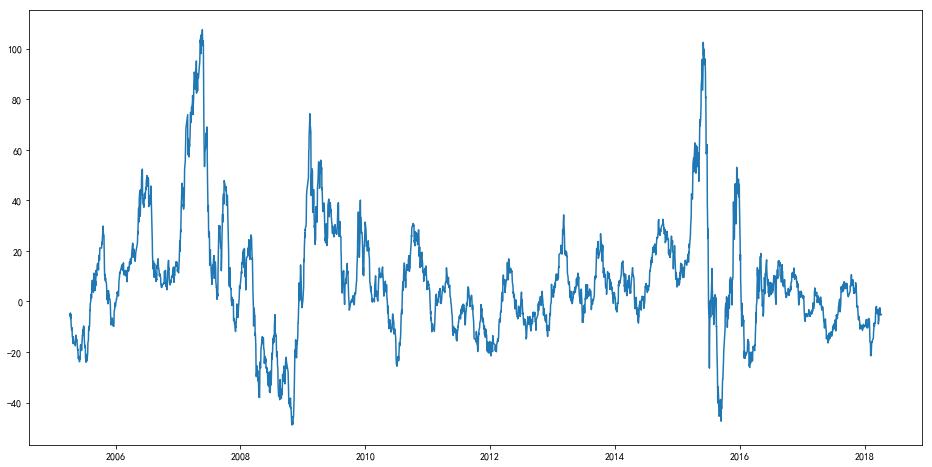

In [15]:
get_stock_gains_2(get_cn_stocks(),60)  

## 根据一个月

Wall time: 34.6 s


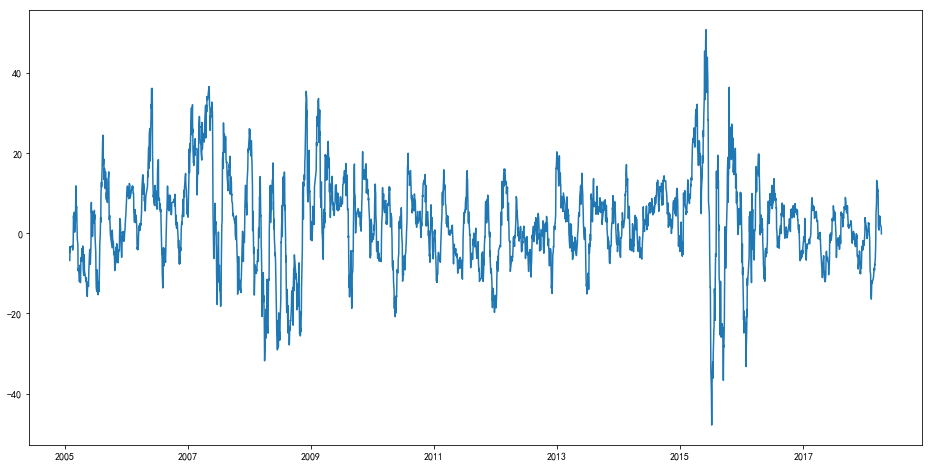

In [16]:
%time get_stock_gains_2(get_cn_stocks(),20)  

# 按照行业分类的股票的涨幅情况

In [17]:
# 我巷保存各个行业的涨幅信息到如下字典中，key为行业名称，而value为这个行业的涨幅信息。
dict_industry_gains={}

## 获得行业情况

In [18]:
# 取得行业分类股票信息
df_industry=ts.get_industry_classified()
df_industry

,code,name,c_name
0,600051,宁波联合,综合行业
1,600209,罗顿发展,综合行业
2,600212,江泉实业,综合行业
3,600256,广汇能源,综合行业
4,600576,祥源文化,综合行业
5,600603,广汇物流,综合行业
6,600614,鹏起科技,综合行业
7,600620,天宸股份,综合行业
8,600622,光大嘉宝,综合行业
9,600624,复旦复华,综合行业


## 获得行业名称列表

In [19]:
# 取得行业列表
lst_industry_name=list(df_industry.drop_duplicates(subset=['c_name'],keep='first')['c_name'])
lst_industry_name   

['综合行业',
 '公路桥梁',
 '化纤行业',
 '机械行业',
 '生物制药',
 '石油行业',
 '玻璃行业',
 '仪器仪表',
 '交通运输',
 '飞机制造',
 '农林牧渔',
 '建筑建材',
 '塑料制品',
 '商业百货',
 '纺织行业',
 '医疗器械',
 '有色金属',
 '供水供气',
 '发电设备',
 '造纸行业',
 '船舶制造',
 '煤炭行业',
 '食品行业',
 '陶瓷行业',
 '纺织机械',
 '钢铁行业',
 '环保行业',
 '酿酒行业',
 '次新股',
 '电器行业',
 '传媒娱乐',
 '化工行业',
 '房地产',
 '金融行业',
 '其它行业',
 '开发区',
 '电子信息',
 '服装鞋类',
 '电子器件',
 '电力行业',
 '汽车制造',
 '家具行业',
 '农药化肥',
 '酒店旅游',
 '水泥行业',
 '物资外贸',
 '摩托车',
 '印刷包装',
 '家电行业']

## 获得某个行业的股票列表

In [20]:
# 取得某个行业所有的股票列表
def get_industry_name(industry_name):
    """根据行业名返回这个行业的股票列表"""
    #有些已经退市的股票，就不要出现啦。
    _all_cn_stock_2=[i[:6] for i in _all_cn_stock]
    lst_return=list(df_industry[df_industry['c_name']==industry_name]['code'])
    lst_return=[i for i in lst_return if i in _all_cn_stock_2]
    return lst_return
get_industry_name('家电行业')

['600060',
 '600261',
 '600336',
 '600690',
 '600839',
 '600854',
 '600870',
 '600983',
 '603366',
 '603519',
 '000016',
 '000100',
 '000333',
 '000418',
 '000521',
 '000533',
 '000541',
 '000651',
 '000921',
 '002005',
 '002032',
 '002035',
 '002076',
 '002242',
 '002260',
 '002290',
 '002403',
 '002429',
 '002473',
 '002508',
 '002543',
 '002668',
 '002677',
 '002681',
 '002705',
 '002723']

## 查看所有行业的涨跌情况

In [21]:
#这里就要遍历所有的行业了
# 保存相关的数据的字典，key为行业名称，value为涨跌情况。
_dict_industry_gains={}
for _industry_name in lst_industry_name:
    #然后对每个行业算涨幅情况。
    _stocks=get_industry_name(_industry_name)
    df_4_1=get_gains_mean(get_stock_gains(_stocks,250))
    _dict_industry_gains[_industry_name]=df_4_1


d:\Anaconda3\lib\site-packages\matplotlib\pyplot.py:537: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  max_open_warning, RuntimeWarning)


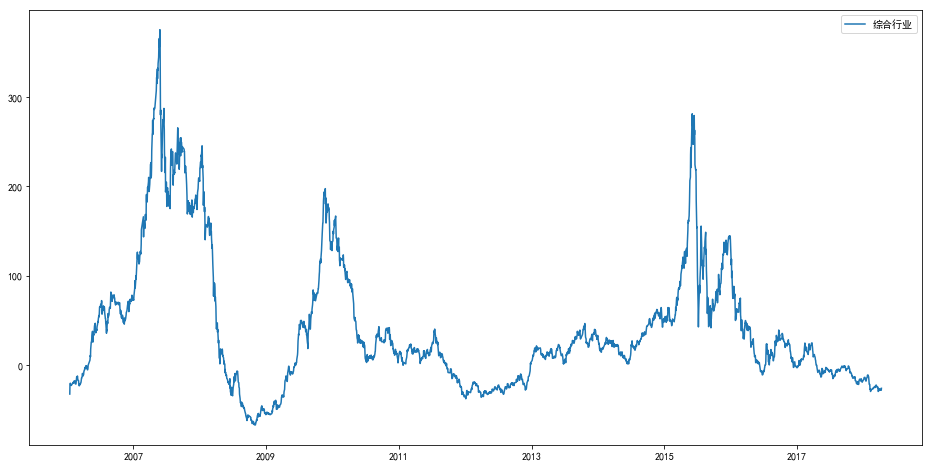

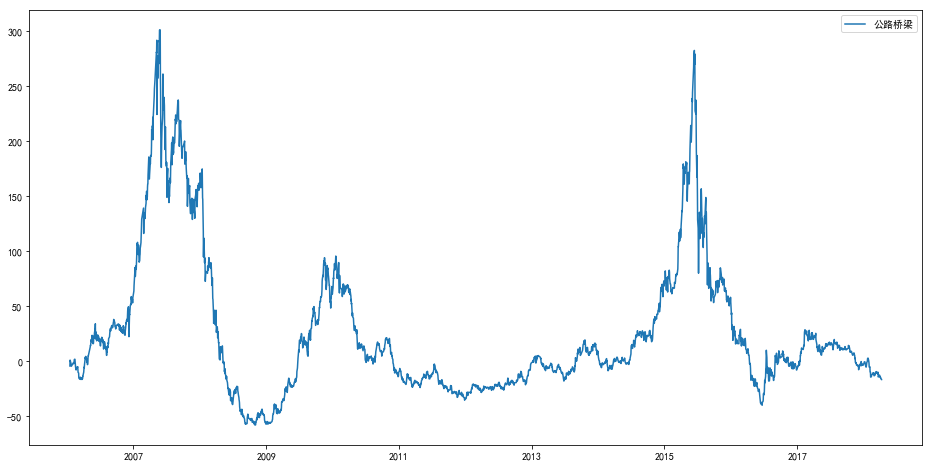

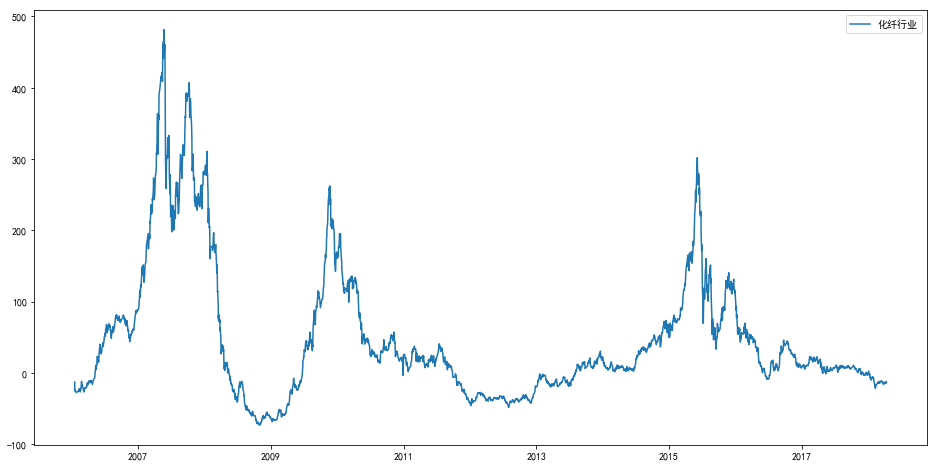

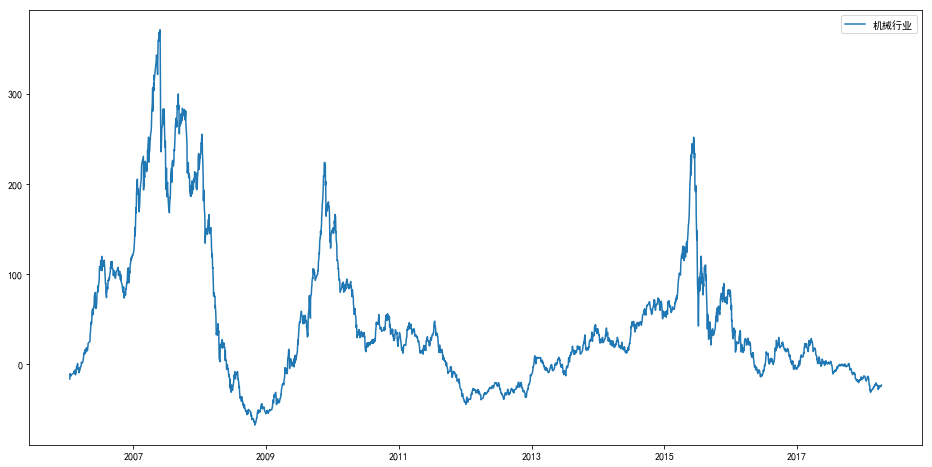

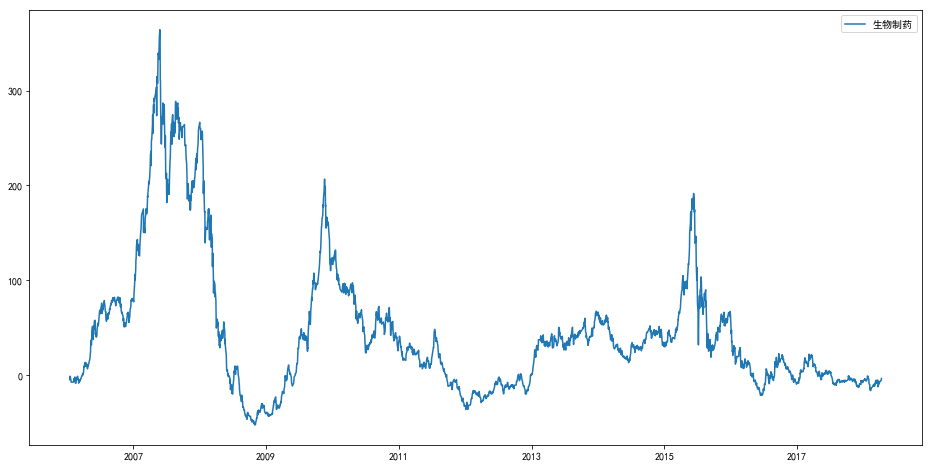

...

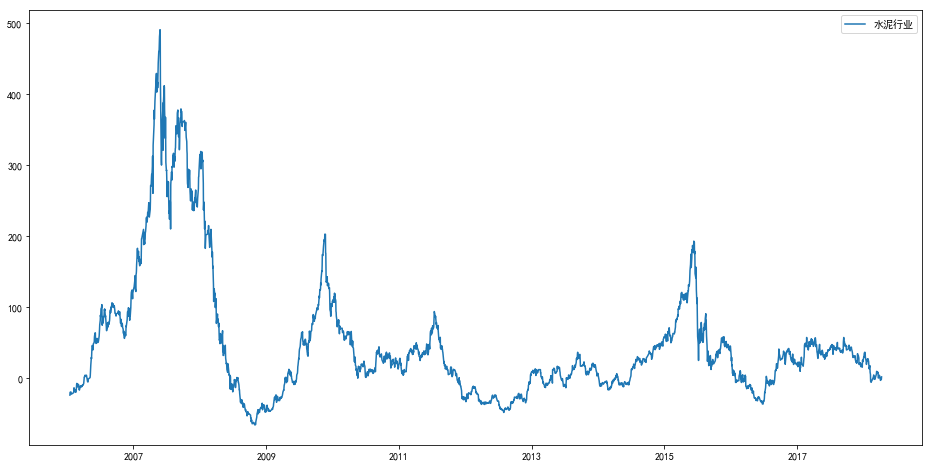

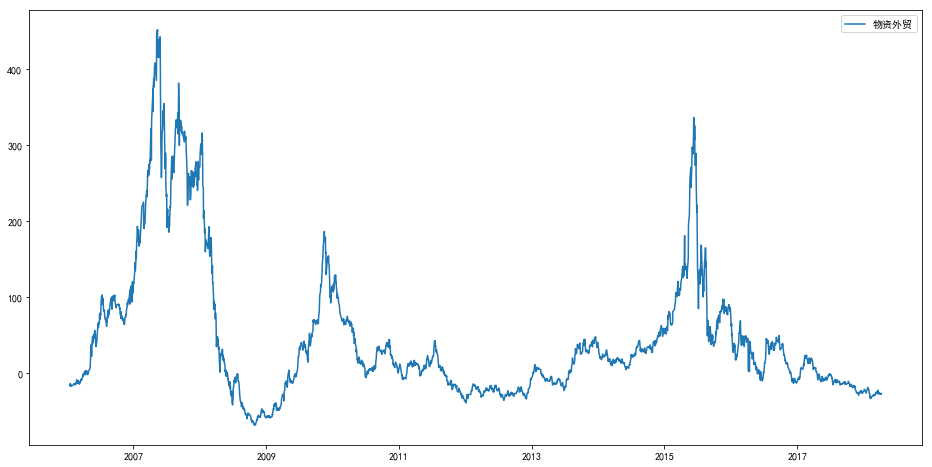

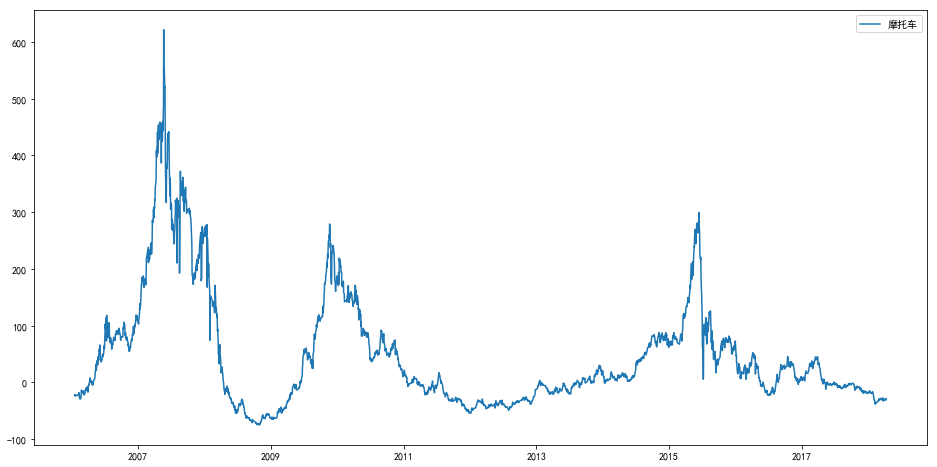

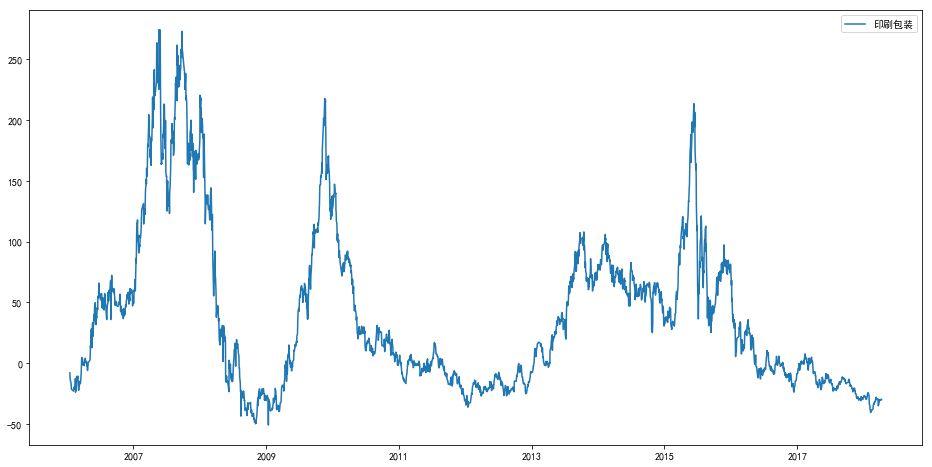

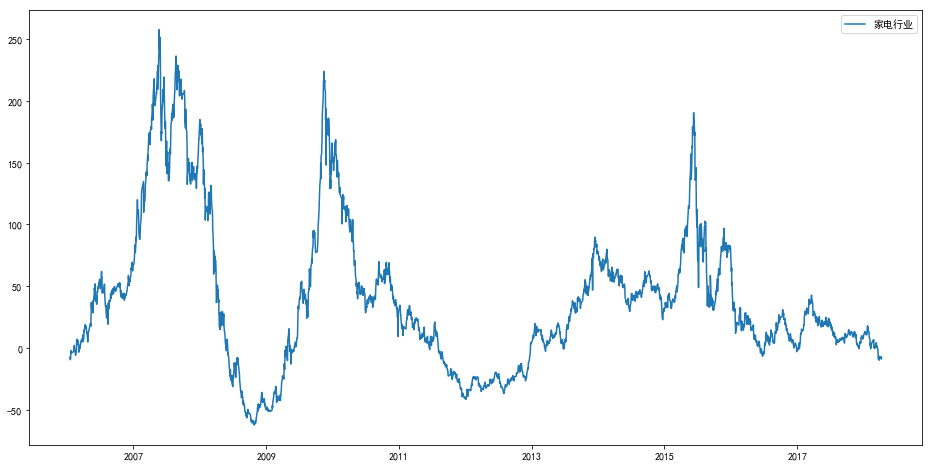

In [22]:
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus']=False #用来正常显示负号
for _key in _dict_industry_gains:
    plt. figure(figsize=(16, 8))
    plt.plot(_dict_industry_gains[_key].index,_dict_industry_gains[_key]['mean'],label=_key)
    plt.savefig("./行业股票涨幅情况/"+_key+".png")
    plt.legend()


# 按照概念分类的股票的涨幅情况

## 获得概念分类列表

In [23]:
df_concept=ts.get_concept_classified()
df_concept

,code,name,c_name
0,600007,中国国贸,外资背景
1,600114,东睦股份,外资背景
2,600132,重庆啤酒,外资背景
3,600182,S佳通,外资背景
4,600595,中孚实业,外资背景
5,600641,万业企业,外资背景
6,600779,水井坊,外资背景
7,600801,华新水泥,外资背景
8,600819,耀皮玻璃,外资背景
9,000001,平安银行,外资背景


## 获得概念列表

In [24]:
# 取得行业列表
lst_concept_name=list(df_concept.drop_duplicates(subset=['c_name'],keep='first')['c_name'])
lst_concept_name   

['外资背景',
 '核电核能',
 '三沙概念',
 '食品安全',
 '锂电池',
 'IPV6概念',
 '前海概念',
 'O2O模式',
 '碳纤维',
 '日韩贸易',
 '聚氨酯',
 '多晶硅',
 '天津自贸',
 '基因测序',
 '资产注入',
 '皖江区域',
 '含B股',
 '空气治理',
 '整体上市',
 '金融改革',
 '本月解禁',
 '粤港澳',
 '固废处理',
 '分拆上市',
 '生态农业',
 '次新股',
 '风能',
 '信托重仓',
 '特斯拉',
 '内贸规划',
 '融资融券',
 '绿色照明',
 '网络游戏',
 '军工航天',
 '沿海发展',
 '文化振兴',
 'QFII重仓',
 '稀缺资源',
 '宽带提速',
 '4G概念',
 '新零售',
 '燃料电池',
 '雄安新区',
 '重组概念',
 '含H股',
 '生物疫苗',
 '广东自贸',
 '上海自贸',
 '卫星导航',
 '稀土永磁',
 '生物育种',
 '参股金融',
 '养老概念',
 '迪士尼',
 '3D打印',
 '社保重仓',
 '陕甘宁',
 '未股改',
 '水域改革',
 '装饰园林',
 '黄金概念',
 '太阳能',
 '上海本地',
 '保障房',
 '京津冀',
 '出口退税',
 '油气改革',
 '草甘膦',
 '地热能',
 '东亚自贸',
 '建筑节能',
 '阿里概念',
 '新三板',
 '三网融合',
 '券商重仓',
 '页岩气',
 '电子支付',
 '充电桩',
 '节能环保',
 '智能电网',
 '超大盘',
 '云计算',
 '基因概念',
 '准ST股',
 '自贸区',
 '抗癌',
 '基金重仓',
 '安防服务',
 '抗流感',
 '央企50',
 '海上丝路',
 'ST板块',
 '铁路基建',
 '互联金融',
 '机器人概念',
 '低碳经济',
 '氢燃料',
 '成渝特区',
 '生物质能',
 '污水处理',
 '猪肉',
 '石墨烯',
 '基因芯片',
 '高校背景',
 '触摸屏',
 '赛马概念',
 '海水淡化',
 '武汉规划',
 '水利建设',
 '节能',
 '甲型流感',
 '电商概念',
 '海工装备',
 '循环经济',
 '军民

## 获得某个概念的股票列表

In [30]:
# 
def get_concep_name(concept_name):
    """根据行业名返回这个行业的股票列表"""
    #有些已经退市的股票，就不要出现啦。
    _all_cn_stock_2=[i[:6] for i in _all_cn_stock]
    lst_return=list(df_concept[df_concept['c_name']==concept_name]['code'])
    lst_return=[i for i in lst_return if i in _all_cn_stock_2]
    return lst_return
get_concep_name('外资背景')

['600007',
 '600114',
 '600132',
 '600182',
 '600595',
 '600641',
 '600779',
 '600801',
 '600819',
 '000001',
 '000005',
 '000541',
 '000608',
 '000659',
 '000869',
 '000895',
 '000932',
 '000935',
 '002032',
 '002047']

## 获得所有概念的涨跌情况

In [33]:
#这里就要遍历所有的行业了
# 保存相关的数据的字典，key为行业名称，value为涨跌情况。
_dict_concept_gains={}
for _concept_name in lst_concept_name:
    #然后对每个行业算涨幅情况。
    _stocks=get_concep_name(_concept_name)
    df_4_1=get_gains_mean(get_stock_gains(_stocks,250))
    _dict_concept_gains[_concept_name]=df_4_1


d:\Anaconda3\lib\site-packages\matplotlib\pyplot.py:537: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  max_open_warning, RuntimeWarning)


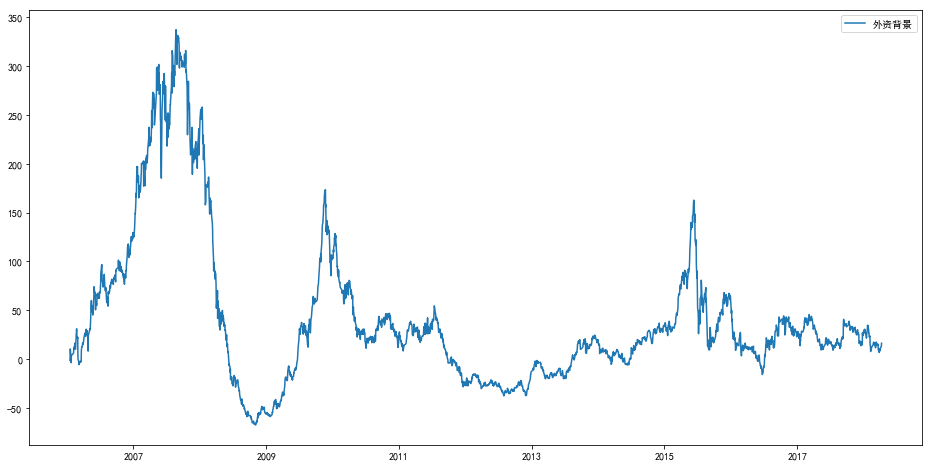

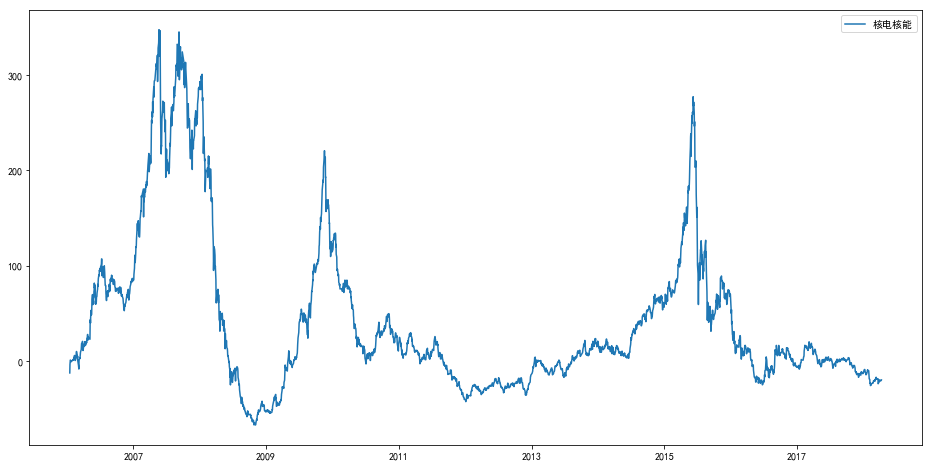

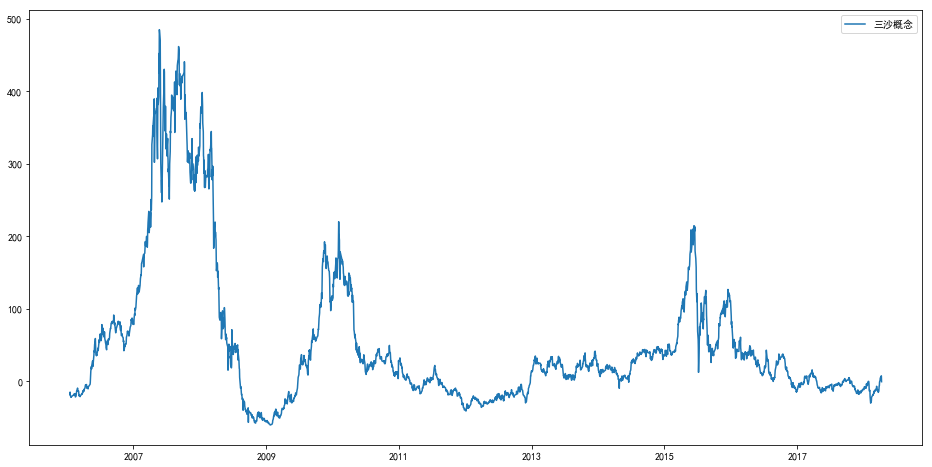

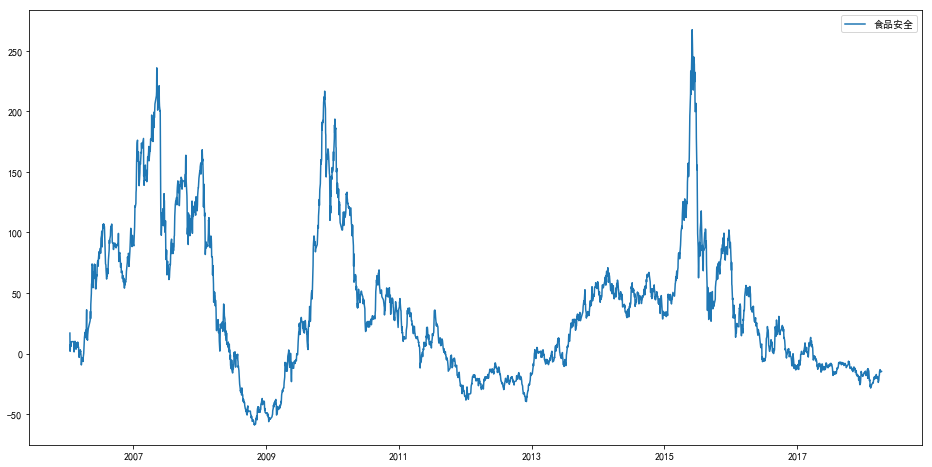

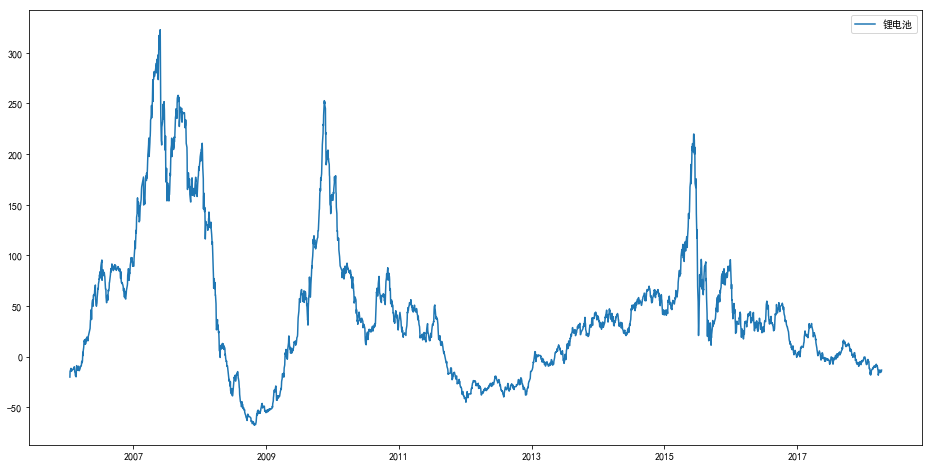

...

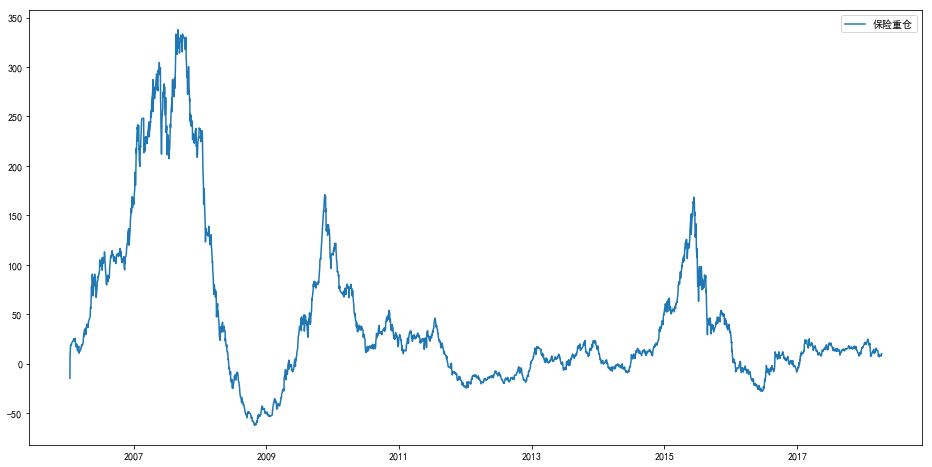

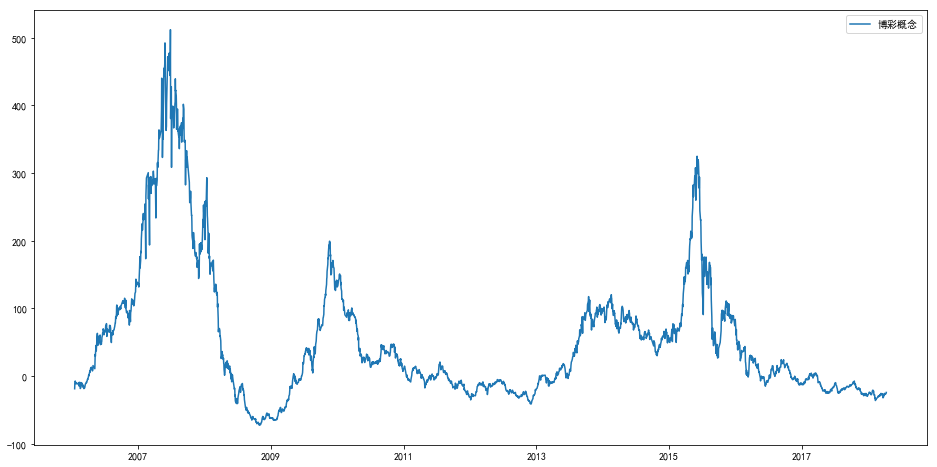

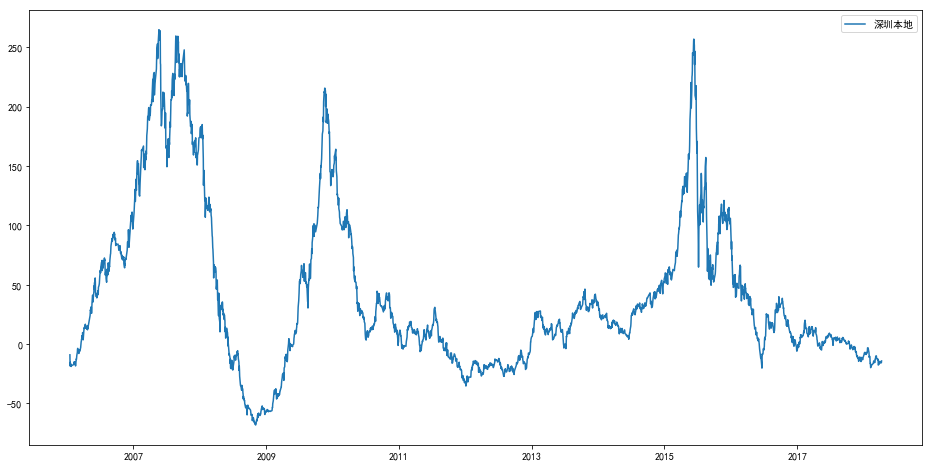

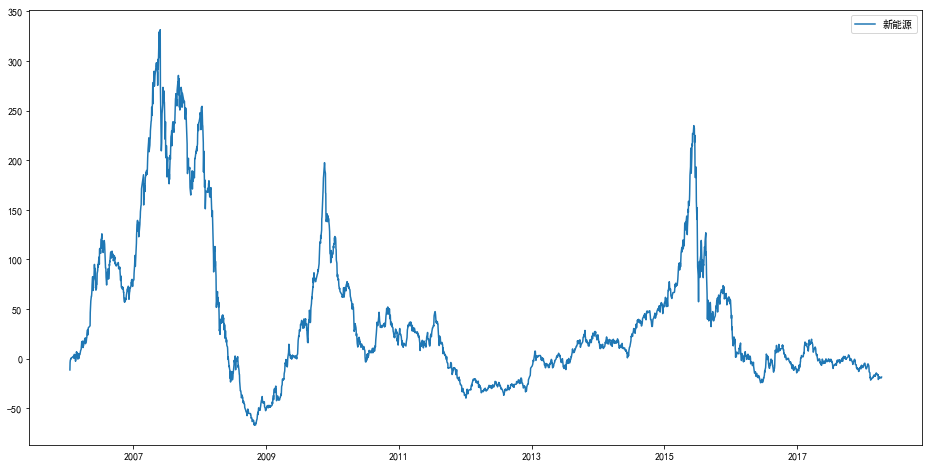

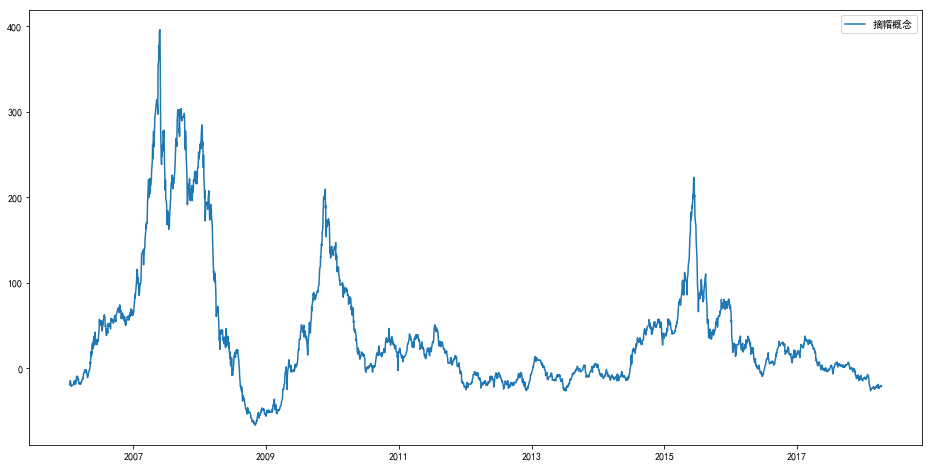

In [34]:
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus']=False #用来正常显示负号
for _key in _dict_concept_gains:
    plt. figure(figsize=(16, 8))
    plt.plot(_dict_concept_gains[_key].index,_dict_concept_gains[_key]['mean'],label=_key)
    plt.savefig("./概念股票涨跌情况/"+_key+".png")
    plt.legend()


# 按照地域分类的股票的涨幅情况

## 获得地域列表

In [39]:
df_area=ts.get_area_classified()
df_area

,code,name,area
0,600696,ST匹凸,上海
1,000668,荣丰控股,上海
2,601021,春秋航空,上海
3,002162,悦心健康,上海
4,600662,强生控股,上海
5,002454,松芝股份,上海
6,603466,风语筑,上海
7,600844,丹化科技,上海
8,002252,上海莱士,上海
9,600836,界龙实业,上海


In [41]:
lst_area_name=list(df_area.drop_duplicates(subset=['area'],keep='first')['area'])
lst_area_name

['上海',
 '云南',
 '内蒙',
 '北京',
 '吉林',
 '四川',
 '天津',
 '宁夏',
 '安徽',
 '山东',
 '山西',
 '广东',
 '广西',
 '新疆',
 '江苏',
 '江西',
 '河北',
 '河南',
 '浙江',
 '海南',
 '深圳',
 '湖北',
 '湖南',
 '甘肃',
 '福建',
 '西藏',
 '贵州',
 '辽宁',
 '重庆',
 '陕西',
 '青海',
 '黑龙江']

## 获得某个地域所有股票的列表

In [43]:
# 取得某个行业所有的股票列表
def get_area_name(area_name):
    """根据行业名返回这个行业的股票列表"""
    #有些已经退市的股票，就不要出现啦。
    _all_cn_stock_2=[i[:6] for i in _all_cn_stock]
    lst_return=list(df_area[df_area['area']==area_name]['code'])
    lst_return=[i for i in lst_return if i in _all_cn_stock_2]
    return lst_return
get_area_name('上海')

['600696',
 '000668',
 '601021',
 '002162',
 '600662',
 '002454',
 '603466',
 '600844',
 '002252',
 '600836',
 '603022',
 '002451',
 '600843',
 '600837',
 '600692',
 '300501',
 '603777',
 '002486',
 '600150',
 '600648',
 '300627',
 '600088',
 '601607',
 '600835',
 '603501',
 '600616',
 '300483',
 '603718',
 '600708',
 '603886',
 '603899',
 '300286',
 '603003',
 '300336',
 '600637',
 '601616',
 '002565',
 '300168',
 '601601',
 '601229',
 '603009',
 '300180',
 '600846',
 '300225',
 '300253',
 '600675',
 '603515',
 '600196',
 '600689',
 '600210',
 '300222',
 '300578',
 '603496',
 '603728',
 '601866',
 '603037',
 '002328',
 '600622',
 '603197',
 '300153',
 '603226',
 '600623',
 '600097',
 '600638',
 '603012',
 '600655',
 '600606',
 '600822',
 '002825',
 '300642',
 '603918',
 '600619',
 '600833',
 '600500',
 '600094',
 '603868',
 '002178',
 '600826',
 '601211',
 '601968',
 '601519',
 '603648',
 '002346',
 '002324',
 '600611',
 '300442',
 '600000',
 '300129',
 '002706',
 '600825',
 '600618',

## 或者所有地域的股票涨跌情况

In [49]:
_dict_area_gains={}
for _area_name in lst_area_name:
    #然后对每个行业算涨幅情况。
    _stocks=get_area_name(_area_name)
    df_4_1=get_gains_mean(get_stock_gains(_stocks,250))
    _dict_area_gains[_area_name]=df_4_1

d:\Anaconda3\lib\site-packages\matplotlib\pyplot.py:537: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  max_open_warning, RuntimeWarning)


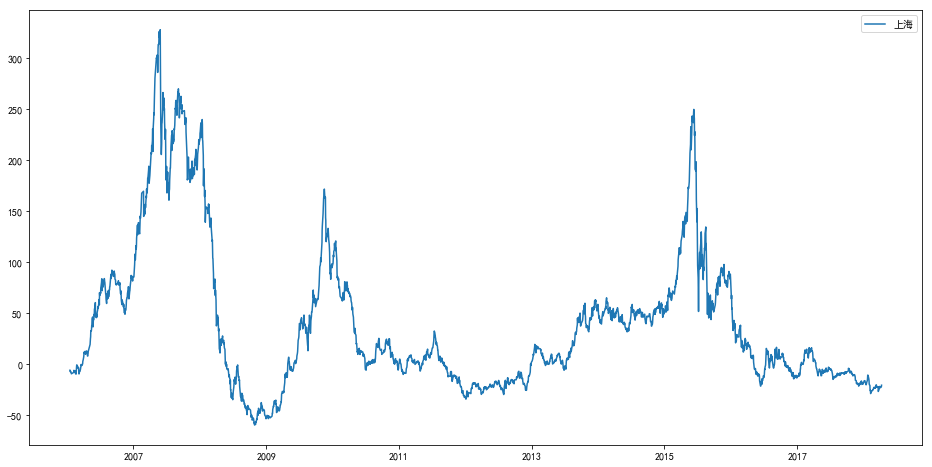

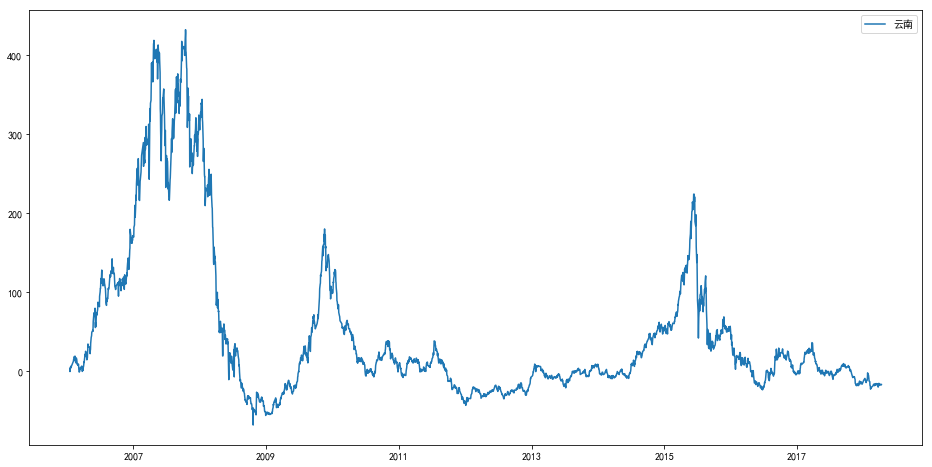

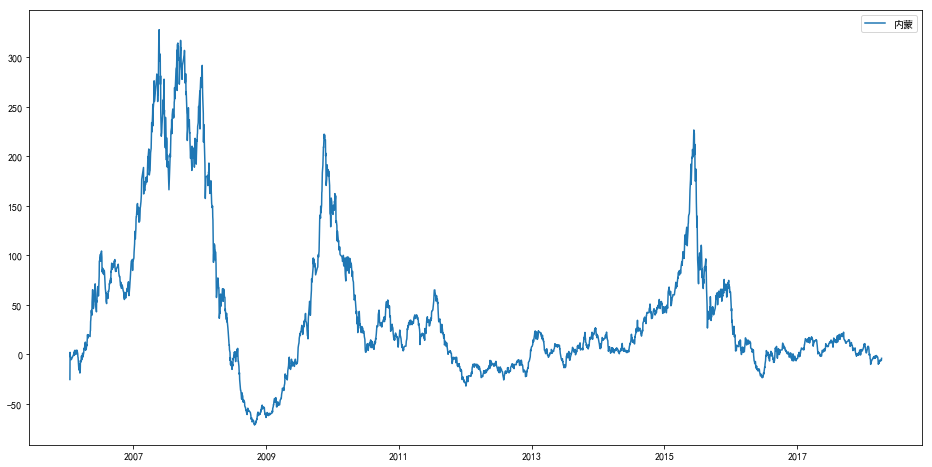

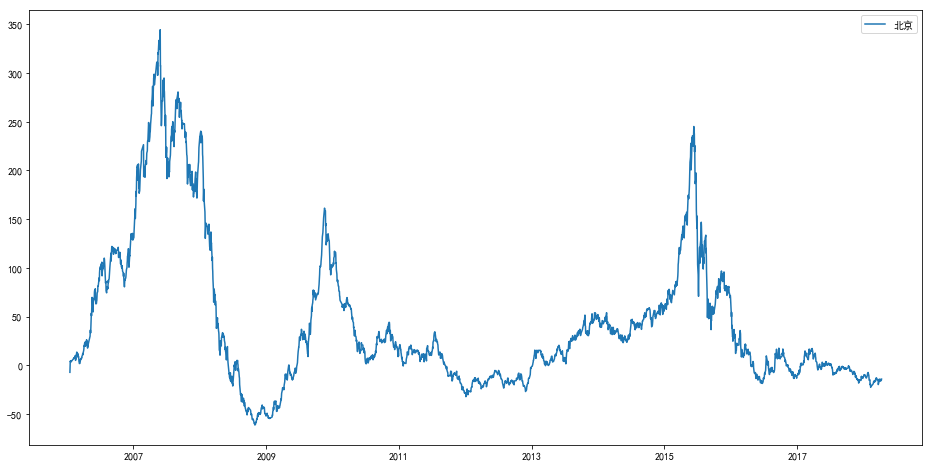

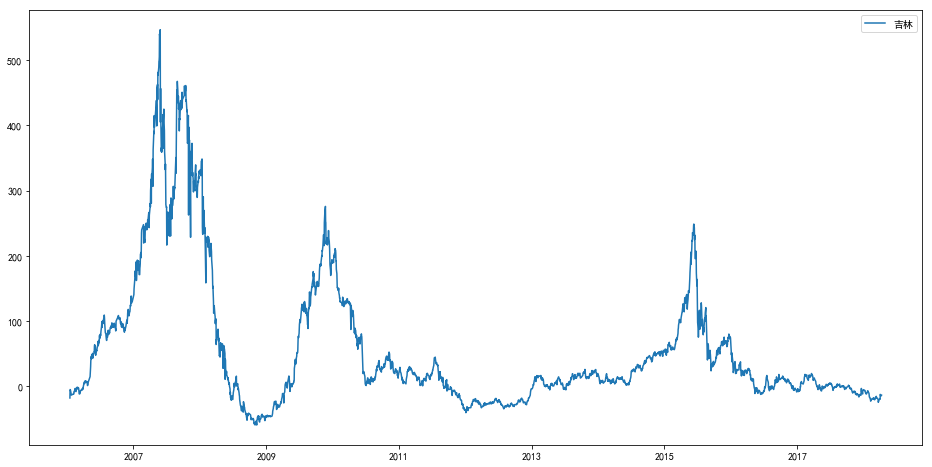

...

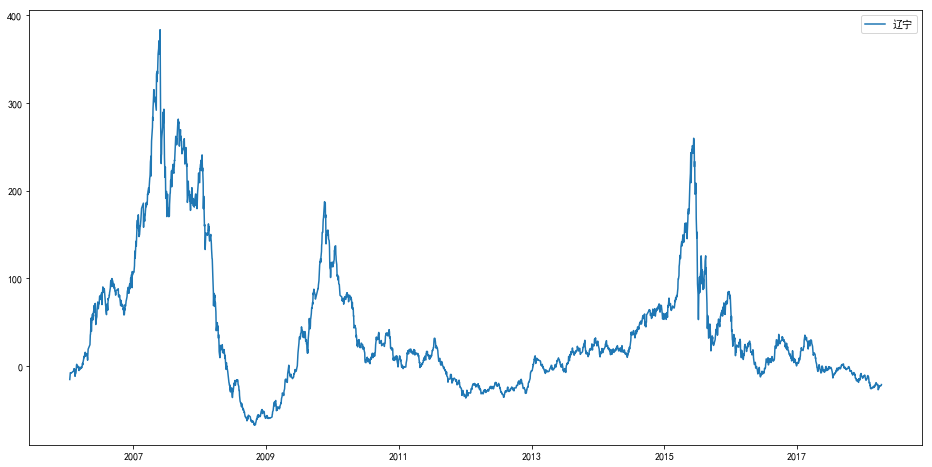

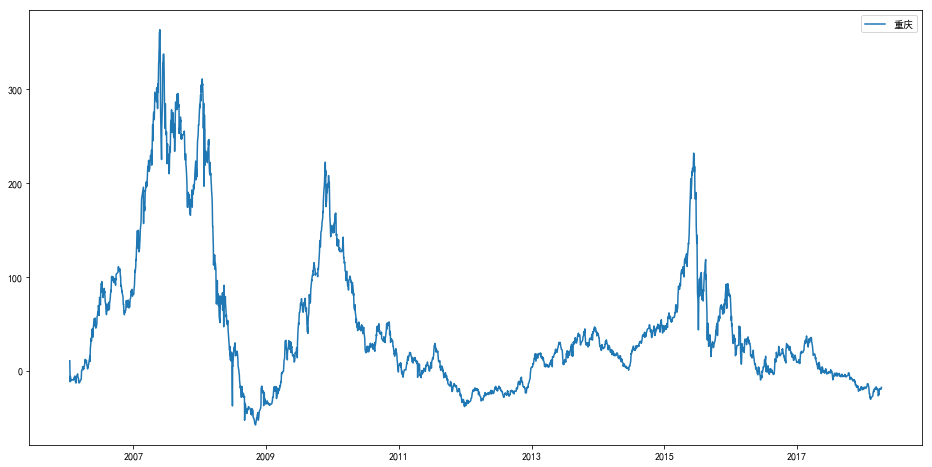

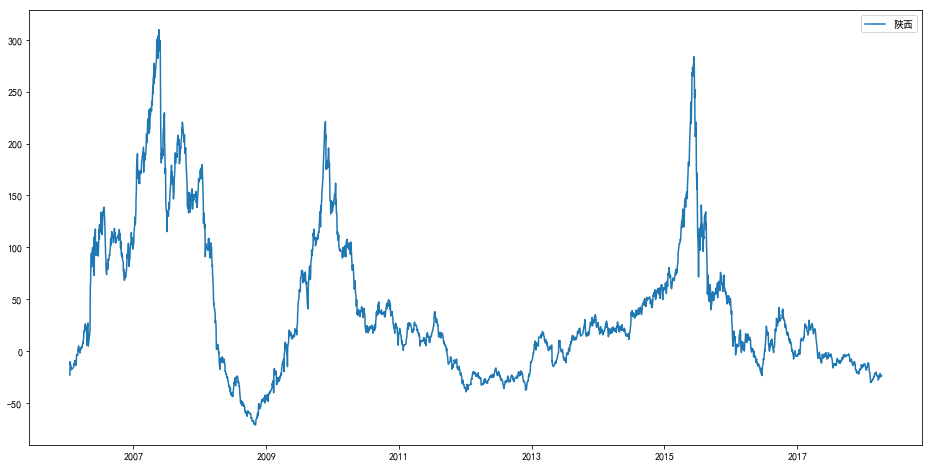

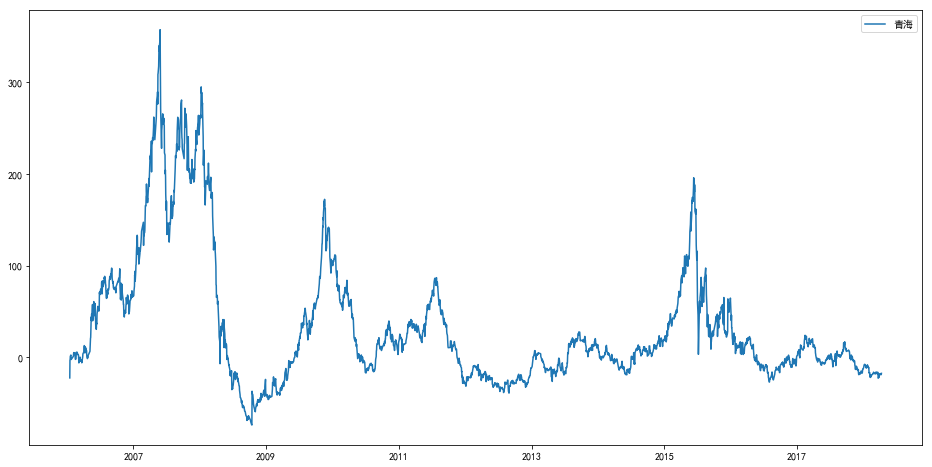

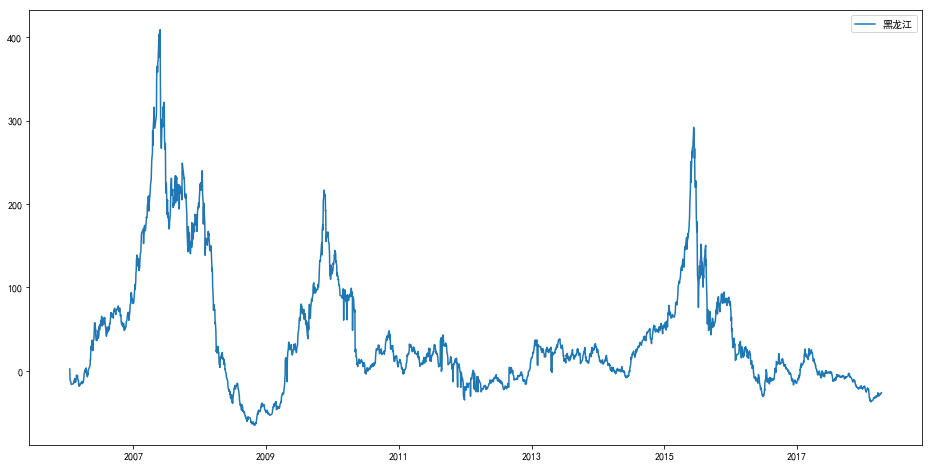

In [51]:
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus']=False #用来正常显示负号
for _key in _dict_area_gains:
    plt. figure(figsize=(16, 8))
    plt.plot(_dict_area_gains[_key].index,_dict_area_gains[_key]['mean'],label=_key)
    plt.savefig("./地域分类股票涨幅情况/"+_key+".png")
    plt.legend()